# Sticky wages and the Euler equation

The `semi_endo_A_*` notebooks read consumption straight off the price index,
`C = P0^power`, which is the **flexible-wage** market-clearing solution: labour supply and
the real wage adjust so that the goods market clears period by period, and the nominal
interest rate never appears.

This notebook keeps the calibration, the time-to-produce distribution and the staggering
structure of [`semi_endo_A_standard.ipynb`](semi_endo_A_standard.ipynb) exactly as they
are, and swaps out only the demand side:

1. **The nominal wage is fully rigid**, `W = 1` for the whole horizon. Prices stay
   flexible, so each firm charges `mu * W / (A_i tprod_i)` and the aggregate price level is
   pinned by productivity alone.
2. **Consumption comes from the household Euler equation** rather than from market
   clearing, so the nominal rate path `i_t` is now a live input.

This is the `euler_path_fixed_wages` block of [`../ss/economic_utils.py`](../ss/economic_utils.py)
and [`../ss/tip_wage_rigidity.ipynb`](../ss/tip_wage_rigidity.ipynb) rebuilt on the
`semi_endo` calibration, self-contained in the style of the other notebooks in this folder.

Two results are worth stating up front, both asserted below:

- Under the baseline rule `i_t = rho`, the sticky-wage Euler path reproduces the flexible-wage
  path **exactly in logs** (`c_t = a_t`, and the flex path is `exp(a_t) - 1`). Under this
  calibration the rigid wage is not, by itself, a source of non-neutrality.
- Inflation is **completely invariant to policy** here. With a rigid `W` and flexible prices,
  `pi_t = -Delta a_t` is pinned by the productivity path, so the nominal rate can move output
  and nothing else. The policy problem below is therefore output stabilisation alone, and it
  has an exact solution.

## Parameters

In [1]:
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
sigma = 5
gamma = 1
eta   = 2
power = (1 + eta) / (-gamma - eta)

beta  = 1 / (1.0 + 0.01)
beta1 = 1 / (1.0 + 0.01 * np.exp(30 / (36.5 * 0.9)))
W = 1                             # rigid nominal wage, fixed for the whole horizon

markup = sigma / (sigma - 1)      # mu, the flexible-price markup over marginal cost
theta  = gamma                    # inverse IES in the Euler equation
rho    = 1 / beta - 1             # steady-state real rate; baseline policy is i_t = rho
T_TAIL = 12                       # unshocked periods appended so the terminal c_T = 0 binds

SHOCK       = 0.97                # baseline: 3% productivity decline
SHOCK_SIZES = [0.99, 0.97, 0.95]  # 1%, 3%, 5%

## Calibration

Unchanged from `semi_endo_A_standard.ipynb`: choose `c` so the mean gap between the
time-to-produce implied by `beta` and by `beta1` is one period.

In [3]:
data     = pd.read_csv('APP_data_usa_goods.csv', index_col=0)
data_tau = data['invtCogsRatio'] * 36.5 / (30 * 0.1)

c_grid   = np.linspace(0, 0.99, 1000)
tau_diff = np.zeros(len(c_grid))

for i, c_try in enumerate(c_grid[1:], start=1):     # skip c=0 (log divergence)
    N_try = -(data_tau) - 1 / np.log(beta * c_try)
    t1 = np.clip(-1 / np.log(beta  * c_try) - N_try, 0, None)
    t2 = np.clip(-1 / np.log(beta1 * c_try) - N_try, 0, None)
    tau_diff[i] = np.mean(np.abs(t1 - t2))

c = np.min(c_grid[np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1))])
print(f'calibrated c = {c:.6f}')

calibrated c = 0.901802


In [4]:
N = np.asarray(-data_tau - 1 / np.log(beta * c))

# floor/ceil rounding, exactly as in semi_endo_A_standard.ipynb
tau = np.clip(-1 / np.log(beta * c) - N, 0, None)
tau_floor, tau_ceil = np.floor(tau), np.ceil(tau)
tprod_ceil  = (beta * c) ** tau_ceil  * (tau_ceil  + N)
tprod_floor = (beta * c) ** tau_floor * (tau_floor + N)
tau = np.where(tprod_ceil > tprod_floor, tau_ceil,
      np.where(tprod_ceil < tprod_floor, tau_floor, tau))
tau = np.clip(tau, 0, None).astype(int)

tau_v   = tau[::-1].copy()
N_v     = N[::-1].copy()
n_firms = len(tau_v)

print(f'{n_firms} firms, tau in [{tau_v.min()}, {tau_v.max()}]')

269 firms, tau in [0, 13]


## Staggering structure

Identical to `semi_endo_A_standard.ipynb`. The rigid wage changes the level of prices, not
which firms have re-optimised by period `t`, so this block is carried over untouched.

In [5]:
def shock_mask(t):
    '''Boolean (period x firm) mask of shocked cells.'''
    t = np.asarray(t)
    n = len(t) + int(t.min())
    m = int(t.max()) + int(t.min())
    missing_count = len(set(range(int(t.max()) + 1)) - set(t))

    M = np.zeros((m + 2, n + missing_count), dtype=bool)
    count = 0
    for i in range(1, m + 2):
        k = int((t == i - 1).sum())
        for j in range(k):
            M[i, n - i - j - count] = True
        if k > 1:
            count += k - 1

    M = np.vstack([M, np.zeros(n + missing_count, dtype=bool)])
    return M[:, 0:n - int(t.min())]


def generate_pattern_array_with_extra_rows(tau, shock=SHOCK):
    '''Original generator, with the shock literal promoted to an argument.'''
    return np.where(shock_mask(tau), shock, 1.0)


M = shock_mask(tau_v)
tprod_v = (beta * c) ** tau_v * (tau_v + N_v)
print(f'mask {M.shape}: {M.sum()} shocked cells over {M.shape[0]} periods')

mask (16, 269): 268 shocked cells over 16 periods


## Prices under a rigid wage

With `W` fixed and prices flexible, firm `i` charges

$$p_{i,t} \;=\; \frac{\mu\,W}{A_{i,t}\,\text{tprod}_i},
\qquad \mu = \frac{\sigma}{\sigma-1}$$

and the CES index is $P_t = \left(\sum_i p_{i,t}^{1-\sigma}\right)^{1/(1-\sigma)}$. Define
the aggregate productivity level

$$a_t \;\equiv\; \log\frac{\mu W}{P_t} \;=\; \frac{1}{\sigma-1}\log\sum_i (A_{i,t}\,\text{tprod}_i)^{\sigma-1},$$

normalised so `a_0 = 0`. Because `W` never moves, the price level is the mirror image of
`a_t` and inflation is `pi_t = -Delta a_t` — the relation `euler_path_fixed_wages` assumes.

`mu * W` is a constant scale factor that cancels out of `a_t`, so `P0` here is the `P0` of
`semi_endo_A_standard.ipynb` times `mu * W`; the assertion below pins that down.
`T_TAIL` unshocked periods are appended so `a_t` has returned to steady state well before
the terminal condition is imposed.

In [6]:
def price_index(shock):
    '''Aggregate price level under a rigid wage W, with an unshocked tail.'''
    A  = generate_pattern_array_with_extra_rows(tau_v, shock)
    A  = np.vstack([A, np.ones((T_TAIL, A.shape[1]))])
    return markup * W * (np.sum((A * tprod_v) ** (sigma - 1), axis=1)) ** (1 / (1 - sigma))


def productivity_level(shock):
    '''Log aggregate productivity a_t, normalised to a_0 = 0.'''
    a = np.log(markup * W) - np.log(price_index(shock))
    return a - a[0]


# same price index as semi_endo_A_standard.ipynb, up to the constant markup * W
A_std  = generate_pattern_array_with_extra_rows(tau_v, 0.97)
P0_std = (np.sum(1 / (A_std * tprod_v) ** (1 - sigma), axis=1)) ** (1 / (1 - sigma))
assert np.allclose(price_index(0.97)[:len(P0_std)] / (markup * W), P0_std)

a_base = productivity_level(SHOCK)
assert np.isclose(a_base[-1], 0), 'tail is too short: a_t has not returned to steady state'
print(f'{len(a_base)} periods, a trough {a_base.min():.5f}, a terminal {a_base[-1]:.2e}')

28 periods, a trough -0.01316, a terminal 0.00e+00


## The Euler equation

$$c_t \;=\; c_{t+1} \;-\; \frac{1}{\theta}\bigl(i_t - \pi_{t+1} - \rho\bigr),
\qquad c_T = 0$$

solved backwards under perfect foresight, with `pi_t = -Delta a_t` from the block above.
This is `euler_path_fixed_wages` from `../ss/economic_utils.py`, written in terms of
`pi_{t+1}` rather than `Delta a_{t+1}` (the same quantity with the sign folded in) and with
the `semi_endo` convention `a_{-1} = a_0`, so `pi_0 = 0`.

In [7]:
def euler_path_fixed_wages(i_path, a_level, theta=theta, rho=rho):
    '''Backward-solve the Euler equation for consumption; returns (c, pi).'''
    i_path  = np.asarray(i_path, float)
    a_level = np.asarray(a_level, float)
    if i_path.shape != a_level.shape:
        raise ValueError('i_path and a_level must have the same shape')

    T = len(i_path)
    da = np.zeros(T)
    da[1:] = a_level[1:] - a_level[:-1]
    pi = -da                                   # rigid wage: prices track productivity 1-for-1

    pi_fwd = np.r_[pi[1:], 0.0]                # E_t pi_{t+1}, deterministic
    c = np.zeros(T + 1)                        # extra slot holds the terminal condition c_T = 0
    for t in range(T - 1, -1, -1):
        c[t] = c[t + 1] - (1.0 / theta) * (i_path[t] - pi_fwd[t] - rho)

    return c[:T], pi


def solve_sticky(shock, i_path=None):
    '''Sticky-wage response. Default policy is the constant baseline rate i_t = rho.'''
    a = productivity_level(shock)
    if i_path is None:
        i_path = np.full(len(a), rho)
    c, pi = euler_path_fixed_wages(i_path, a)
    return c, pi, a


def solve_flex(shock):
    '''Flexible-wage benchmark: the market-clearing path of semi_endo_A_standard.ipynb.'''
    P0 = price_index(shock)
    C  = P0 ** power / P0[0] ** power - 1
    C_pad = np.zeros(len(C) + 1)
    C_pad[1:] = C
    return C, -(C_pad[1:] - C_pad[:-1])


C_sticky, pi_sticky, a_base = solve_sticky(SHOCK)
C_flex,   pi_flex           = solve_flex(SHOCK)

print(f'{100*(1-SHOCK):.0f}% shock, baseline policy i_t = rho')
print(f'  sticky wage : c trough {C_sticky.min():.5f}, pi peak {pi_sticky.max():.5f}')
print(f'  flexible    : C trough {C_flex.min():.5f}, pi peak {pi_flex.max():.5f}')

3% shock, baseline policy i_t = rho
  sticky wage : c trough -0.01316, pi peak 0.00681
  flexible    : C trough -0.01307, pi peak 0.00674


## Why the two coincide

With `theta = gamma = 1` and `i_t = rho`, the Euler equation collapses to
`c_t = c_{t+1} + pi_{t+1} = c_{t+1} - Delta a_{t+1}`. Iterating forward from `c_T = 0` with
`a_T = 0` gives `c_t = a_t` exactly.

On the flexible-wage side `power = (1+eta)/(-gamma-eta) = -1`, so
`C_t = P_0/P_t - 1 = exp(a_t) - 1`. The two are therefore the *same* path, one in logs and
one in levels, and differ only at second order (about 4 basis points at the trough of a 3%
shock).

So the rigid wage on its own buys no extra non-neutrality here — the wedge has to come from
policy, which is the next section. This is a property of the calibration, not an identity:
it relies on `theta = 1` and on `power = -1`, and would break under any other `gamma`.

In [8]:
assert np.allclose(C_sticky, a_base), 'c_t = a_t should hold exactly when theta = 1 and i = rho'
assert np.allclose(C_flex, np.exp(a_base) - 1)

print(f'max |c_sticky - a|            {np.abs(C_sticky - a_base).max():.2e}')
print(f'max |C_flex - (exp(a) - 1)|   {np.abs(C_flex - (np.exp(a_base) - 1)).max():.2e}')
print(f'max |c_sticky - C_flex|       {np.abs(C_sticky - C_flex).max():.2e}  (second order)')

max |c_sticky - a|            0.00e+00
max |C_flex - (exp(a) - 1)|   3.33e-16
max |c_sticky - C_flex|       8.62e-05  (second order)


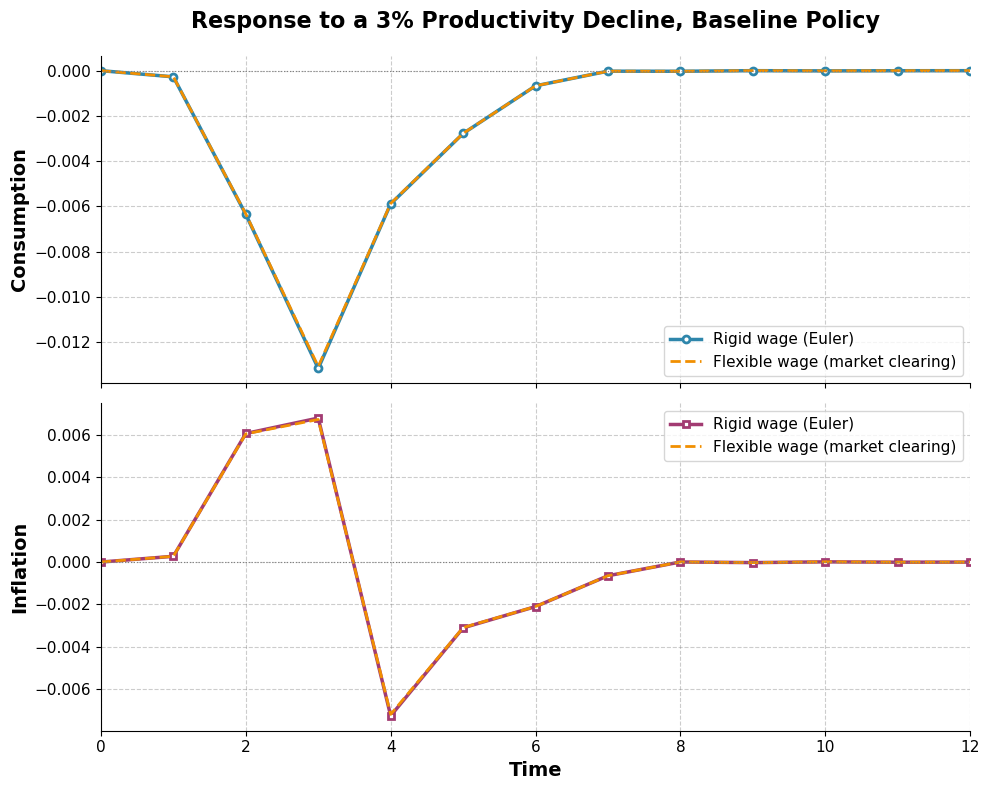

In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

ax1.plot(C_sticky, lw=2.5, marker='o', markersize=5, color='#2E86AB',
         markerfacecolor='white', markeredgewidth=2, label='Rigid wage (Euler)')
ax1.plot(C_flex, lw=2, ls='--', color='#F18F01', label='Flexible wage (market clearing)')
ax2.plot(pi_sticky, lw=2.5, marker='s', markersize=5, color='#A23B72',
         markerfacecolor='white', markeredgewidth=2, label='Rigid wage (Euler)')
ax2.plot(pi_flex, lw=2, ls='--', color='#F18F01', label='Flexible wage (market clearing)')

ax1.set_title(f'Response to a {100*(1-SHOCK):.0f}% Productivity Decline, Baseline Policy',
              fontsize=16, weight='bold', pad=20)
ax1.set_ylabel('Consumption', fontsize=14, weight='bold')
ax2.set_ylabel('Inflation', fontsize=14, weight='bold')
ax2.set_xlabel('Time', fontsize=14, weight='bold')

for ax in (ax1, ax2):
    ax.set_xlim(0, 12)
    ax.grid(True, linestyle='--', alpha=0.4, color='gray')
    ax.tick_params(axis='both', which='major', labelsize=11)
    ax.axhline(0, color='gray', linestyle=':', linewidth=0.8)
    ax.legend(fontsize=11)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('../semi_endo_A_sticky_wages.png', dpi=150)
plt.show()

## Policy

Now the Euler equation earns its keep. Sweep the nominal rate over the first `SEQ_LEN`
periods with `itertools.product`, as in `../ss/tip_wage_rigidity.ipynb`, and pick the
sequence minimising the usual loss `sum(c^2) + sum(pi^2)`.

The inflation half of that loss is a constant: `pi_t = -Delta a_t` depends only on the
productivity path, so every rate sequence in the grid delivers the same `pi`. Policy is
choosing output alone, and the problem has an exact interior solution — set

$$i_t \;=\; \rho + \pi_{t+1}$$

and the Euler equation gives `c_t = c_{t+1}` for all `t`, hence `c = 0` throughout. The
grid search is bounded by `r_choice`, so it only approaches this.

In [10]:
SEQ_LEN   = 4
r_choice  = np.linspace(0.0, 0.02, 5)
r_arrange = np.array(list(itertools.product(r_choice, repeat=SEQ_LEN)))

T    = len(a_base)
loss = np.zeros(len(r_arrange))
C_consumption = np.zeros((len(r_arrange), T))
pi_inflation  = np.zeros((len(r_arrange), T))

for k, r_vec in enumerate(r_arrange):
    i_path = np.full(T, rho)
    i_path[:SEQ_LEN] = r_vec
    c_k, pi_k = euler_path_fixed_wages(i_path, a_base)
    C_consumption[k], pi_inflation[k] = c_k, pi_k
    loss[k] = np.sum(c_k ** 2) + np.sum(pi_k ** 2)

best     = int(np.argmin(loss))
baseline = int(np.where(np.all(np.isclose(r_arrange, rho), axis=1))[0][0])

assert np.allclose(pi_inflation, pi_inflation[0]), 'inflation should not depend on the rate path'

print(f'{len(r_arrange)} rate sequences over the first {SEQ_LEN} periods')
print(f'  baseline i_t = rho = {rho:.4f}   loss {loss[baseline]:.6f}')
print(f'  grid optimum {np.round(r_arrange[best], 4)}   loss {loss[best]:.6f}')
print(f'  inflation identical across all {len(r_arrange)} sequences')

625 rate sequences over the first 4 periods
  baseline i_t = rho = 0.0100   loss 0.000407
  grid optimum [0.01  0.015 0.015 0.   ]   loss 0.000205
  inflation identical across all 625 sequences


In [11]:
# the exact output-stabilising rule, unconstrained by the grid
pi_fwd = np.r_[pi_sticky[1:], 0.0]
i_star = rho + pi_fwd
c_star, pi_star = euler_path_fixed_wages(i_star, a_base)

assert np.allclose(c_star, 0), 'i_t = rho + pi_{t+1} should zero out consumption'
assert np.allclose(pi_star, pi_sticky)

print(f'i_t = rho + pi_(t+1):  max |c| = {np.abs(c_star).max():.2e}, '
      f'loss {np.sum(c_star**2) + np.sum(pi_star**2):.6f}')
print(f'rate path over the first {SEQ_LEN} periods: {np.round(i_star[:SEQ_LEN], 5)}')

i_t = rho + pi_(t+1):  max |c| = 0.00e+00, loss 0.000151
rate path over the first 4 periods: [0.01027 0.01608 0.01681 0.00273]


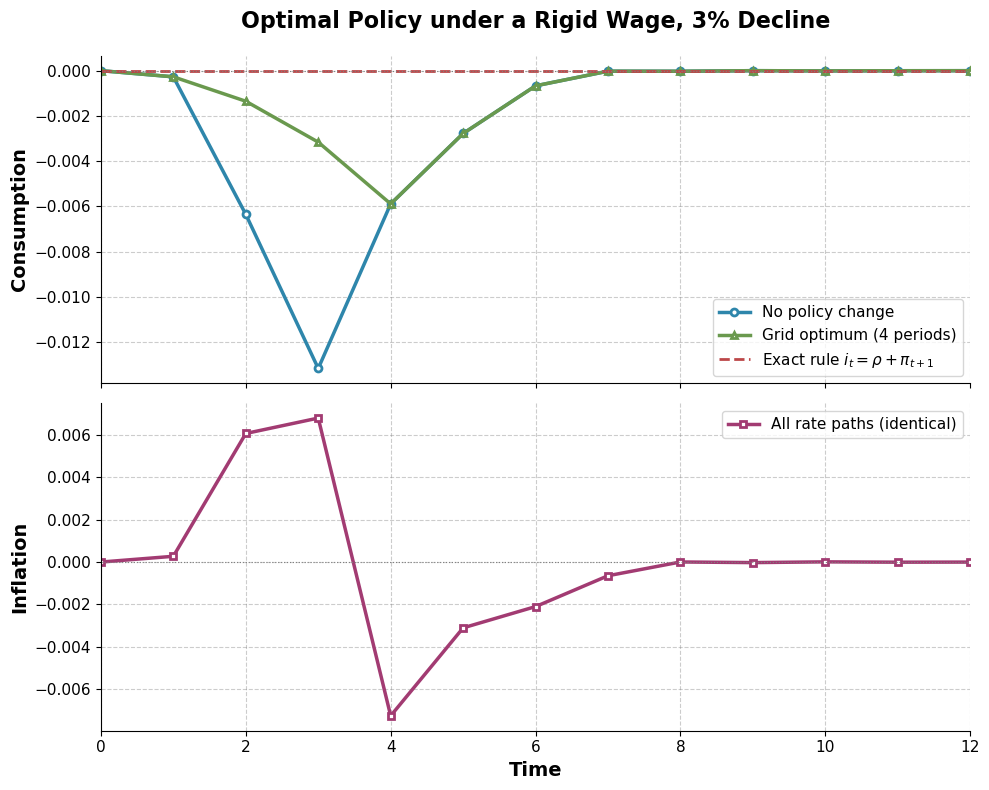

In [12]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

ax1.plot(C_consumption[baseline], lw=2.5, marker='o', markersize=5, color='#2E86AB',
         markerfacecolor='white', markeredgewidth=2, label='No policy change')
ax1.plot(C_consumption[best], lw=2.5, marker='^', markersize=5, color='#6A994E',
         markerfacecolor='white', markeredgewidth=2, label=f'Grid optimum ({SEQ_LEN} periods)')
ax1.plot(c_star, lw=2, ls='--', color='#BC4749', label=r'Exact rule $i_t=\rho+\pi_{t+1}$')

ax2.plot(pi_sticky, lw=2.5, marker='s', markersize=5, color='#A23B72',
         markerfacecolor='white', markeredgewidth=2, label='All rate paths (identical)')

ax1.set_title(f'Optimal Policy under a Rigid Wage, {100*(1-SHOCK):.0f}% Decline',
              fontsize=16, weight='bold', pad=20)
ax1.set_ylabel('Consumption', fontsize=14, weight='bold')
ax2.set_ylabel('Inflation', fontsize=14, weight='bold')
ax2.set_xlabel('Time', fontsize=14, weight='bold')

for ax in (ax1, ax2):
    ax.set_xlim(0, 12)
    ax.grid(True, linestyle='--', alpha=0.4, color='gray')
    ax.tick_params(axis='both', which='major', labelsize=11)
    ax.axhline(0, color='gray', linestyle=':', linewidth=0.8)
    ax.legend(fontsize=11)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('../semi_endo_A_sticky_wages_policy.png', dpi=150)
plt.show()

## Shock size

As in the flexible-wage notebook, the lag distribution is fixed, so the size of the decline
is the only comparative static left. Under the baseline rule the response is close to
proportional in it.

  shock    c trough     pi peak        loss
     1%    -0.00444     0.00228    0.000047
     3%    -0.01316     0.00681    0.000407
     5%    -0.02164     0.01129    0.001099


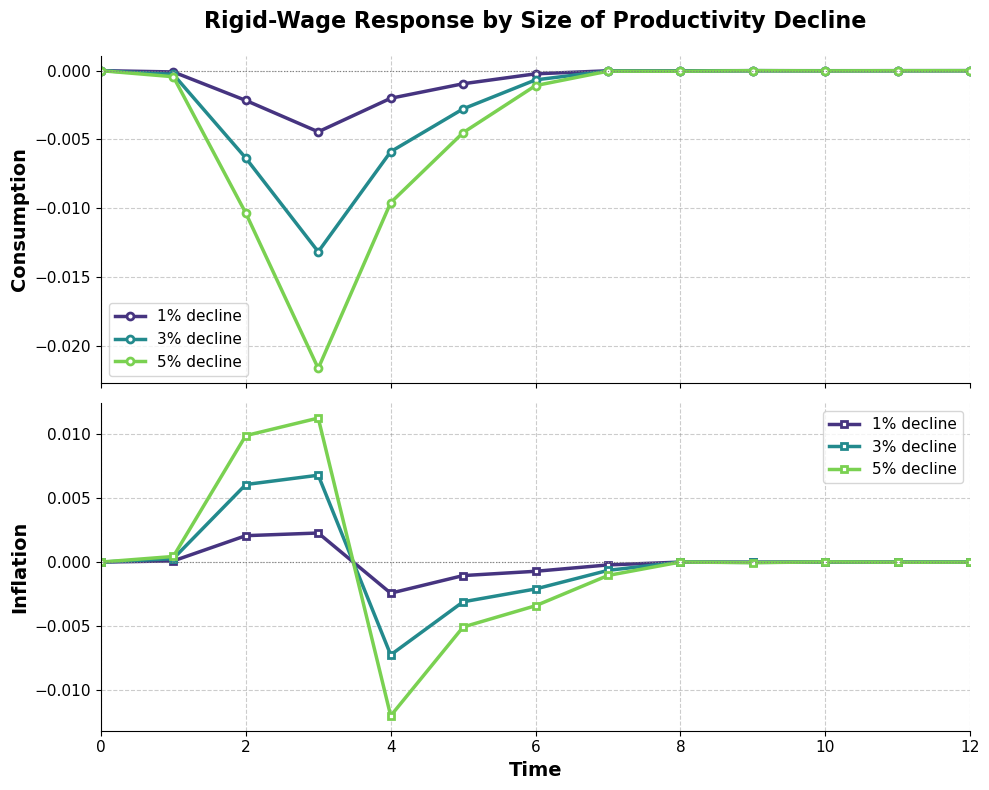

In [13]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
colors = plt.cm.viridis(np.linspace(0.15, 0.8, len(SHOCK_SIZES)))

print(f'{"shock":>7} {"c trough":>11} {"pi peak":>11} {"loss":>11}')
for s, col in zip(SHOCK_SIZES, colors):
    c_s, pi_s, _ = solve_sticky(s)
    lab = f'{100*(1-s):.0f}% decline'
    ax1.plot(c_s,  lw=2.5, marker='o', markersize=5, color=col,
             markerfacecolor='white', markeredgewidth=2, label=lab)
    ax2.plot(pi_s, lw=2.5, marker='s', markersize=5, color=col,
             markerfacecolor='white', markeredgewidth=2, label=lab)
    print(f'{100*(1-s):>6.0f}% {c_s.min():>11.5f} {pi_s.max():>11.5f} '
          f'{np.sum(c_s**2) + np.sum(pi_s**2):>11.6f}')

ax1.set_title('Rigid-Wage Response by Size of Productivity Decline',
              fontsize=16, weight='bold', pad=20)
ax1.set_ylabel('Consumption', fontsize=14, weight='bold')
ax2.set_ylabel('Inflation', fontsize=14, weight='bold')
ax2.set_xlabel('Time', fontsize=14, weight='bold')

for ax in (ax1, ax2):
    ax.set_xlim(0, 12)
    ax.grid(True, linestyle='--', alpha=0.4, color='gray')
    ax.tick_params(axis='both', which='major', labelsize=11)
    ax.axhline(0, color='gray', linestyle=':', linewidth=0.8)
    ax.legend(fontsize=11)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('../semi_endo_A_sticky_wages_sizes.png', dpi=150)
plt.show()

## Summary

- Replacing the market-clearing rule `C = P0^power` with a household Euler equation under a
  fully rigid wage leaves the baseline path unchanged: `c_t = a_t` exactly, against
  `C_t = exp(a_t) - 1` for the flexible-wage benchmark. The two agree to second order.
  This rests on `theta = gamma = 1` and `power = -1`, and is not a general property.
- Inflation is invariant to the nominal rate. With `W` rigid and prices flexible,
  `pi_t = -Delta a_t` is a function of the productivity path alone, so all 625 rate
  sequences in the sweep produce the same `pi`. There is no output–inflation trade-off to
  resolve, only an output gap to close.
- The loss is therefore minimised exactly by `i_t = rho + pi_{t+1}`, which delivers `c = 0`
  at every date. The bounded grid search recovers roughly half the loss reduction; the gap
  is the grid's coarseness, not a feature of the model.

**Next.** The bite has to come from somewhere the rigid wage can interact with. Two
candidates:

- **Sticky prices as well as wages** — if firms cannot reset `p_i` on impact, `pi_t` stops
  tracking `-Delta a_t`, inflation becomes policy-sensitive, and the trade-off reappears.
- **Partial wage adjustment** — let `W_t` close a fraction `phi` of the gap to its
  flexible-wage target each period (`phi = 0.5` in `../ss/tip_wage_rigidity.ipynb`). `phi = 0`
  is this notebook and `phi = 1` is `semi_endo_A_standard.ipynb`, so the interesting cases
  sit strictly between the two paths plotted above.

*Caveat inherited from the original construction:* the staggering places 268 shocked cells
for 269 firms, so one firm is never hit, and 3 of the 268 land on a firm whose `tau` does
not match the period. Preserved here for comparability rather than corrected.